<p class="hz-kicker">Week 6 · Live session</p>

# Forests, boosting, and decisions

Altamar's tuned tree beat the straight line, but management now wants one model it can trust and a clear reason to use it. Today you combine many trees into forests and boosting, compare every model on the same test bookings, open the black box, and turn the winner into two decisions and a ten-minute presentation.

<ul class="hz-lesson-meta"><li>4 hours</li><li>9 ideas</li><li>Runs in your browser</li><li>Case: comparison and presentation</li></ul>

**Today's plan.** Block 1 (ideas 01–04): why many trees beat one, the two ways of combining them, and a fair scoreboard for Altamar's two questions. Block 2 (ideas 05–09): what drives the predictions, two decisions the models support, how to present them to management, and the case clinic for your final hand-in.

Run this cell first. You don't need to read it.

In [1]:
# Run this cell first. You don't need to read it.
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier, GradientBoostingRegressor,
                              HistGradientBoostingRegressor, HistGradientBoostingClassifier)
from sklearn.metrics import mean_absolute_error, r2_score, roc_auc_score, roc_curve
from sklearn.inspection import permutation_importance

DATA = "https://raw.githubusercontent.com/hizocar/mba-business-analytics-1/main/docs/datasets/"
df = pd.read_csv(DATA + "altamar_bookings_clean.csv")
df["arrival_month"] = pd.to_datetime(df["arrival_date"]).dt.month
HOTELS = ["Santiago", "Viña del Mar", "Puerto Varas"]
TEXT = ["hotel", "room_type", "customer_type", "channel", "deposit", "country"]
NUMBERS = ["lead_time_days", "nights", "weekend_nights", "adults", "children", "repeat_guest",
           "previous_cancellations", "special_requests", "parking", "arrival_month"]

# The same inputs and train/test splits as in weeks 3 to 5 (25% of bookings kept aside for the test)
X_rate, y_rate = df[NUMBERS + TEXT], df["adr"]
X_cancel, y_cancel = df[NUMBERS + TEXT + ["adr"]], df["canceled"]
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_rate, y_rate, test_size=0.25, random_state=42)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_cancel, y_cancel, test_size=0.25, random_state=42, stratify=y_cancel)


def model(estimator, month_as_category=False):
    """Turn the text columns into 0/1 columns (as pd.get_dummies(drop_first=True) did in week 5), then fit `estimator`."""
    text = TEXT + (["arrival_month"] if month_as_category else [])
    encode = make_column_transformer(("passthrough", lambda X: [c for c in X.columns if c not in text]),
                                     (OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), text))
    return make_pipeline(encode, estimator)


def rate_scores(name, m):
    p = m.predict(Xr_test)
    return {"model": name, "typical error (USD)": round(mean_absolute_error(yr_test, p), 1),
            "R²": round(r2_score(yr_test, p), 3)}


def cancel_scores(name, m):
    p = m.predict_proba(Xc_test)[:, 1]
    top150 = np.argsort(-p)[:150]
    return {"model": name, "AUC": round(roc_auc_score(yc_test, p), 3),
            "cancelled, of the 150 riskiest": int(yc_test.values[top150].sum())}


def pd_curve(m, X, column, grid, proba=False):
    """Partial dependence: give every booking in X the same value of `column`, average the predictions."""
    out = []
    for v in grid:
        X_v = X.assign(**{column: v})
        out.append(m.predict_proba(X_v)[:, 1].mean() if proba else m.predict(X_v).mean())
    return np.array(out)


plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"Santiago": "#2b6f78", "Viña del Mar": "#c85a24", "Puerto Varas": "#7a4f8e"}
print(f"{len(df):,} bookings loaded. Training: {len(Xr_train):,} bookings · Test: {len(Xr_test):,} bookings.")

5,964 bookings loaded. Training: 4,473 bookings · Test: 1,491 bookings.


## <span class="hz-step-n">01</span> Previously: one tree is jumpy

Week 5 ended with two **tuned trees**, their depth chosen by cross-validation: depth 10 for the rate and depth 4 for cancellations. On the test bookings the rate tree took R² from 0.74 (the line, month as a category) to **0.89**, and the typical error from USD 20.5 to **USD 13.3**; the cancellation tree took AUC from 0.74 (logistic) to **0.75**.

But a single tree is **jumpy**. Its first question decides every question below it, so a slightly different sample of bookings can grow a quite different tree, and quote a different price for the same room. No revenue manager would trust such a colleague.

The cell grows week 5's tuned rate tree (depth 10) three times, each on a different random half of the training bookings, and prices the same three test bookings. Look at the **spread** column: how far apart the three quotes are.

In [2]:
halves = [Xr_train.sample(frac=0.5, random_state=s).index for s in [1, 2, 3]]
three = Xr_test.iloc[[0, 5, 8]]                     # three test bookings to follow
names = [f"{h}, {r}, month {m}" for h, r, m in zip(three["hotel"], three["room_type"], three["arrival_month"])]
tree_quotes, quotes = [], {}
for i, idx in enumerate(halves, start=1):
    tree = model(DecisionTreeRegressor(max_depth=10, random_state=42)).fit(Xr_train.loc[idx], yr_train.loc[idx])
    tree_quotes.append(tree.predict(Xr_test))
    quotes[f"tree {i}"] = tree.predict(three).round(0)
table = pd.DataFrame(quotes, index=names)
table["spread"] = table.max(axis=1) - table.min(axis=1)
table["actual"] = yr_test.loc[three.index].round(0).values
print(table)
spread_trees = np.ptp(np.array(tree_quotes), axis=0).mean()
print(f"\nAcross all {len(Xr_test):,} test bookings, the three trees disagree by USD {spread_trees:.1f} on average.")

                                  tree 1  tree 2  tree 3  spread  actual
Viña del Mar, Superior, month 11   118.0   146.0   114.0    32.0   139.0
Puerto Varas, Standard, month 7    156.0   178.0   147.0    31.0   154.0
Santiago, Standard, month 10        92.0   125.0    96.0    33.0   107.0

Across all 1,491 test bookings, the three trees disagree by USD 19.9 on average.


**Business takeaway:** each of these rooms gets three quotes more than USD 30 apart, depending only on which half of the history the tree happened to see; across all test bookings, about USD 20. The fix sounds like management common sense: don't ask one expert, ask a panel, and combine their answers.

## <span class="hz-step-n">02</span> Random forests: many trees voting

A **random forest** grows hundreds of trees and averages them. Three ideas make the trees different from each other, so that their mistakes cancel out:

1. **Bootstrap samples.** Each tree learns from its own sample of bookings, drawn at random *with replacement*: some bookings appear twice, about a third not at all.
2. **Random inputs.** At each question a tree may only choose among a random subset of the inputs, so one strong input cannot dominate every tree.
3. **Averaging.** For the rate, the forest's quote is the average of the trees' quotes. For cancellations, it is the share of trees that vote "cancel".

<div class="hz-widget" data-widget="forest-vote">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_6_Live/">open this session on the course website</a> to use it.</p>
</div>

**Try it:** press *Run the forest* for each booking. Booking A gets a unanimous vote; Booking E splits the trees almost in half. Then press *One tree at a time* and read why each tree votes as it does: they disagree because each one saw different bookings and different inputs.

The cell grows a forest of 200 trees for the nightly rate (every leaf keeps at least 3 bookings) and asks each of its trees to price the same three bookings.

In [3]:
forest = model(RandomForestRegressor(n_estimators=200, min_samples_leaf=3, random_state=42))
forest.fit(Xr_train, yr_train)
encoded = forest[:-1].transform(three)                      # the bookings as the trees see them
per_tree = np.array([t.predict(encoded) for t in forest[-1].estimators_])
for j, name in enumerate(names):
    print(f"{name}: the 200 trees quote USD {per_tree[:, j].min():.0f} to {per_tree[:, j].max():.0f}; "
          f"the forest says USD {per_tree[:, j].mean():.0f} (actual USD {table['actual'].iloc[j]:.0f})")

Viña del Mar, Superior, month 11: the 200 trees quote USD 91 to 176; the forest says USD 128 (actual USD 139)
Puerto Varas, Standard, month 7: the 200 trees quote USD 82 to 181; the forest says USD 158 (actual USD 154)
Santiago, Standard, month 10: the 200 trees quote USD 69 to 134; the forest says USD 97 (actual USD 107)


The histogram shows the 200 quotes for the July booking at Puerto Varas. Look at how wide the individual quotes are, and where their average lands.

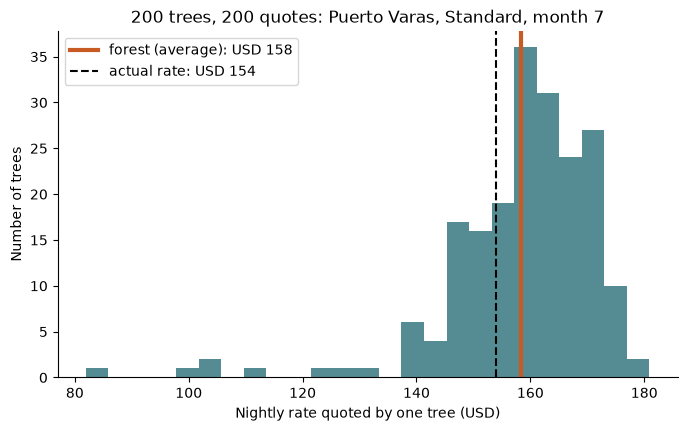

In [4]:
plt.hist(per_tree[:, 1], bins=25, color="#2b6f78", alpha=0.8)
plt.axvline(per_tree[:, 1].mean(), color="#c85a24", lw=3, label=f"forest (average): USD {per_tree[:, 1].mean():.0f}")
plt.axvline(table["actual"].iloc[1], color="black", ls="--", label=f"actual rate: USD {table['actual'].iloc[1]:.0f}")
plt.title(f"200 trees, 200 quotes: {names[1]}")
plt.xlabel("Nightly rate quoted by one tree (USD)")
plt.ylabel("Number of trees")
plt.legend()
plt.show()

The same experiment as in idea 01, now with forests: three forests of 100 trees, each grown on one of the same three halves. Compare the spread with the trees' spread.

In [5]:
forest_quotes = []
for idx in halves:
    f = model(RandomForestRegressor(n_estimators=100, min_samples_leaf=3, random_state=42)).fit(Xr_train.loc[idx], yr_train.loc[idx])
    forest_quotes.append(f.predict(Xr_test))
spread_forests = np.ptp(np.array(forest_quotes), axis=0).mean()
print(f"Average disagreement on the same test bookings: three trees USD {spread_trees:.1f}, three forests USD {spread_forests:.1f}.")
print(f"The forests' quotes move {1 - spread_forests / spread_trees:.0%} less when the history changes.")

Average disagreement on the same test bookings: three trees USD 19.9, three forests USD 8.5.
The forests' quotes move 57% less when the history changes.


<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "Why does a random forest give steadier quotes than a single tree?", "options": ["Each of its trees is deeper and more accurate than a single tree", "It averages many trees that each saw different bookings and inputs, so their individual quirks cancel out", "It checks itself on the test bookings while it learns"], "answer": 1, "why": "Each tree is as jumpy as before, but their errors point in different directions. Averaging 200 of them cancels much of the noise. The test bookings are never used for learning.", "code": false}</script>
</div>

## <span class="hz-step-n">03</span> Gradient boosting: trees that fix each other's mistakes

A forest grows its trees **side by side**, independently. **Gradient boosting** grows them **in a row**, like a team where each member reviews the previous one's work:

1. Start with the simplest prediction: the average rate.
2. Look at the errors. A small tree learns where the prediction is too low and where it is too high.
3. Add a *damped* copy of that correction (the **learning rate**, say 10% of it).
4. Repeat with the errors that are left.

Each tree is small and weak on its own; a hundred of them, each fixing what the others missed, make a strong model.

<div class="hz-widget" data-widget="boosting-steps">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_6_Live/">open this session on the course website</a> to use it.</p>
</div>

**Try it:** press *Play* with the learning rate at 0.3 and watch the error bars shrink, January first, then the July holidays. Then try 1.0 and 0.1. How many trees does each need before the typical error stops falling?

The same thing in code: scikit-learn's `GradientBoostingRegressor` on the simulator's 60 bookings, with the month as the only input. Change the learning rate and compare with the simulator.

In [6]:
# ✏️ Change these settings
LEARNING_RATE = 0.3

pv = df[(df["hotel"] == "Puerto Varas") & (df["room_type"] == "Standard")]
sample = pv.groupby("arrival_month").sample(5, random_state=42)          # the simulator's 60 bookings
gb = GradientBoostingRegressor(max_depth=2, min_samples_leaf=5, learning_rate=LEARNING_RATE,
                               n_estimators=40, random_state=42).fit(sample[["arrival_month"]], sample["adr"])
errors = [mean_absolute_error(sample["adr"], p) for p in gb.staged_predict(sample[["arrival_month"]])]
print(f"Average only: typical error USD {(sample['adr'] - sample['adr'].mean()).abs().mean():.0f}")
for k in [1, 2, 5, 10, 20, 40]:
    print(f"After {k:>2} trees: USD {errors[k - 1]:.0f}")

Average only: typical error USD 30
After  1 trees: USD 25
After  2 trees: USD 22
After  5 trees: USD 17
After 10 trees: USD 15
After 20 trees: USD 14
After 40 trees: USD 14


Now the real problem: all inputs, all bookings. `HistGradientBoostingRegressor` is scikit-learn's fast boosting (by default 100 small trees, learning rate 0.1). The cell trains it with three learning rates and records the **test** error after each tree.

In [7]:
curves = {}
for lr in [0.03, 0.1, 0.5]:
    m = model(HistGradientBoostingRegressor(learning_rate=lr, random_state=42)).fit(Xr_train, yr_train)
    test_encoded = m[:-1].transform(Xr_test)
    curves[lr] = [mean_absolute_error(yr_test, p) for p in m[-1].staged_predict(test_encoded)]
    if lr == 0.1:
        boost = m                                                    # the default: our boosting model
    best = int(np.argmin(curves[lr])) + 1
    print(f"Learning rate {lr}: after 100 trees USD {curves[lr][-1]:.1f}; best USD {min(curves[lr]):.1f} at tree {best}")

Learning rate 0.03: after 100 trees USD 11.4; best USD 11.4 at tree 100


Learning rate 0.1: after 100 trees USD 8.4; best USD 8.4 at tree 100


Learning rate 0.5: after 100 trees USD 9.8; best USD 9.3 at tree 20


The chart draws the three curves: typical test error against the number of trees.

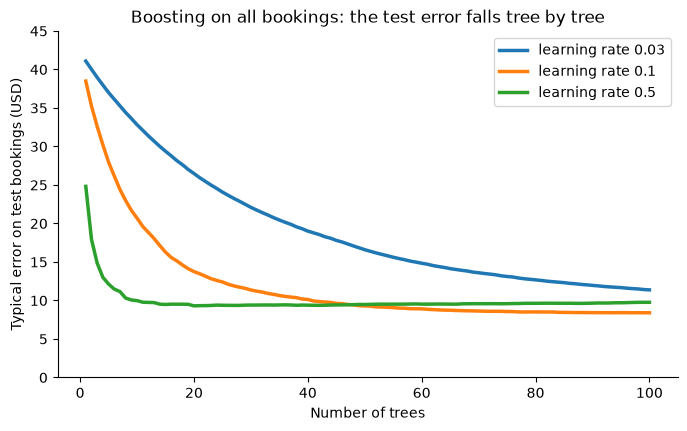

In [8]:
for lr, c in curves.items():
    plt.plot(range(1, len(c) + 1), c, lw=2.5, label=f"learning rate {lr}")
plt.title("Boosting on all bookings: the test error falls tree by tree")
plt.xlabel("Number of trees")
plt.ylabel("Typical error on test bookings (USD)")
plt.ylim(0, 45)
plt.legend()
plt.show()

**Reading the chart.** With learning rate **0.03** the model is still learning after 100 trees (USD 11.4): steps too small. With **0.5** it is fastest, reaches USD 9.3 at tree 20, then gets slightly *worse* (USD 9.8): big steps start copying noise from the training bookings, the overfitting you met in week 5. The default **0.1** ends best here, at **USD 8.4**. Rule of thumb: a smaller learning rate needs more trees, and is usually safer.

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "In gradient boosting, what does tree number 50 learn from?", "options": ["The original nightly rates, exactly like tree 1", "The errors that are still left after the first 49 trees", "A random half of the bookings, independently of the other trees"], "answer": 1, "why": "Each new tree is fitted to the current errors, so it fixes what the previous trees got wrong. Independent trees on random samples is the forest's recipe, not boosting's.", "code": false}</script>
</div>

## <span class="hz-step-n">04</span> The scoreboard

A fair comparison has three rules: the **same training bookings**, the **same test bookings**, and a **metric that fits the decision**. For the rate: the typical error in USD (MAE) and R². For cancellations: AUC, and a business number, how many real cancellations each model puts among the 150 bookings it flags as riskiest (about the top 10% of the test bookings).

The cell retrains week 5's line and tuned tree for the rate (the forest and boosting are already trained) and prints one row per model.

In [9]:
rate_models = {
    "Linear regression": model(LinearRegression(), month_as_category=True).fit(Xr_train, yr_train),
    "Tuned tree (depth 10)": model(DecisionTreeRegressor(max_depth=10, random_state=42)).fit(Xr_train, yr_train),
    "Random forest": forest,
    "Gradient boosting": boost,
}
rate_board = pd.DataFrame([rate_scores(n, m) for n, m in rate_models.items()]).set_index("model")
print(rate_board)

                       typical error (USD)     R²
model                                            
Linear regression                     20.5  0.738
Tuned tree (depth 10)                 13.3  0.891
Random forest                         10.3  0.935
Gradient boosting                      8.4  0.956


What the typical error means in money: Altamar sold about 7,300 room-nights a year (bookings that were not cancelled). The cell multiplies.

In [10]:
room_nights = df.loc[df["canceled"] == 0, "nights"].sum() / 2              # two years of arrivals
print(f"Room-nights sold per year: {room_nights:,.0f}\n")
for name, err in rate_board["typical error (USD)"].items():
    print(f"{name:<22} USD {err:>4.1f} a night → about USD {err * room_nights:>7,.0f} a year priced too high or too low")

Room-nights sold per year: 7,318

Linear regression      USD 20.5 a night → about USD 150,019 a year priced too high or too low
Tuned tree (depth 10)  USD 13.3 a night → about USD  97,329 a year priced too high or too low
Random forest          USD 10.3 a night → about USD  75,375 a year priced too high or too low
Gradient boosting      USD  8.4 a night → about USD  61,471 a year priced too high or too low


**Business takeaway:** from the line to boosting, the typical pricing error falls from **USD 20.5 to USD 8.4 a night**, under 7% of the average rate of USD 127; week 5's tuned tree stood at USD 13.3. Over a year that is about USD 88,000 less mispricing than the line. Not all of it is revenue: some errors are prices set too high, which lose bookings instead. But it is the size of the prize.

Now cancellations. The cell trains the four classifiers (the logistic model and the depth-4 tree exactly as in week 5) on the same training bookings and scores them on the same test bookings.

In [11]:
cancel_models = {
    "Logistic regression": model(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))).fit(Xc_train, yc_train),
    "Tuned tree (depth 4)": model(DecisionTreeClassifier(max_depth=4, random_state=42)).fit(Xc_train, yc_train),
    "Random forest": model(RandomForestClassifier(n_estimators=200, min_samples_leaf=3, random_state=42)).fit(Xc_train, yc_train),
    "Gradient boosting": model(HistGradientBoostingClassifier(random_state=42)).fit(Xc_train, yc_train),
}
cancel_board = pd.DataFrame([cancel_scores(n, m) for n, m in cancel_models.items()]).set_index("model")
print(cancel_board)

                        AUC  cancelled, of the 150 riskiest
model                                                      
Logistic regression   0.739                              92
Tuned tree (depth 4)  0.752                             117
Random forest         0.771                             123
Gradient boosting     0.770                             121


**A refresher from week 4.** Every threshold turns probabilities into a list of "will cancel" bookings; the ROC curve records, for every threshold, the share of real cancellations caught (up) against the share of false alarms (right). AUC is the area under it.

<div class="hz-widget" data-widget="roc">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_6_Live/">open this session on the course website</a> to use it.</p>
</div>

The cell draws the ROC curves of the four models on the same test bookings. Higher and further to the left is better.

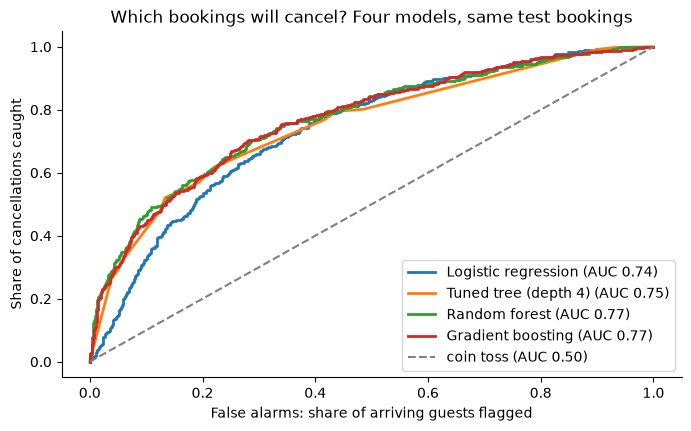

In [12]:
for name, m in cancel_models.items():
    fpr, tpr, _ = roc_curve(yc_test, m.predict_proba(Xc_test)[:, 1])
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC {cancel_board.loc[name, 'AUC']:.2f})")
plt.plot([0, 1], [0, 1], color="grey", ls="--", label="coin toss (AUC 0.50)")
plt.title("Which bookings will cancel? Four models, same test bookings")
plt.xlabel("False alarms: share of arriving guests flagged")
plt.ylabel("Share of cancellations caught")
plt.legend()
plt.show()

**Reading the scoreboard.** AUC moves less than R²: 0.74 → 0.75 → 0.77 → 0.77. Cancelling is a human decision, and two identical bookings can go either way, so no model gets close to 1. The forest and boosting are **tied**.

But look at the top of the list: of the 150 bookings each model flags as riskiest, the logistic model catches 92 real cancellations, week 5's tree 117, the forest 123 and boosting 121. For an overbooking desk that is **about 30 more correct calls per 150 flags** than the line: rooms resold that would otherwise sit empty.

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "On the same test bookings, the forest's AUC is 0.771 and boosting's is 0.770. What should Altamar conclude?", "options": ["The forest is clearly better and must be the one used", "They are tied in practice; choose on other grounds such as speed, stability or ease of explaining", "AUC is the wrong metric, so the comparison is invalid"], "answer": 1, "why": "A difference of 0.001 is well within the noise of 1,491 test bookings; another split could reverse it. When two models tie on accuracy, the decision moves to other criteria.", "code": false}</script>
</div>

☕ **Break: 10 minutes.** After the break: what drives the predictions, two decisions the models support, and how to present them to Altamar's management.

## <span class="hz-step-n">05</span> Opening the black box

A tree you can read like a flowchart; 200 trees, you cannot. Management will still ask two questions, and both have answers:

- **Which inputs matter?** *Permutation importance*: shuffle one column of the test bookings (breaking its link with the outcome while keeping its values) and measure how much worse the model gets. Big damage, important input.
- **How do they matter?** *Partial dependence*: change one input for every booking, keep everything else as it was, and watch the average prediction move.

The cell shuffles each input of the test bookings five times and records how many USD the boosting model's typical error grows.

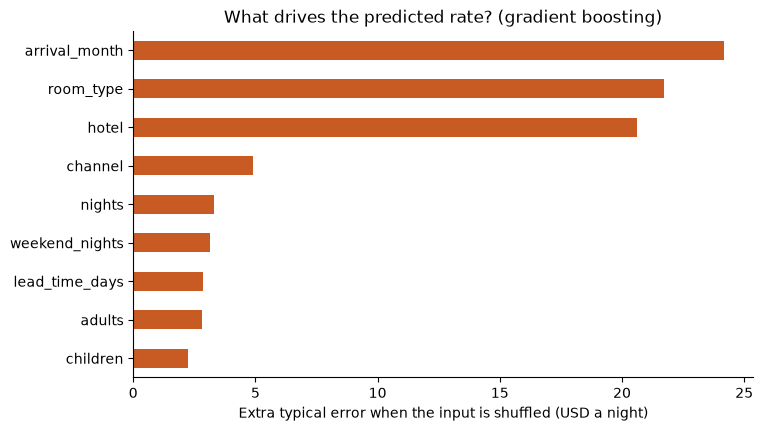

In [13]:
imp = permutation_importance(boost, Xr_test, yr_test, scoring="neg_mean_absolute_error", n_repeats=5, random_state=42)
rate_imp = pd.Series(imp.importances_mean, index=Xr_test.columns).sort_values()
rate_imp.tail(9).plot.barh(color="#c85a24")
plt.title("What drives the predicted rate? (gradient boosting)")
plt.xlabel("Extra typical error when the input is shuffled (USD a night)")
plt.show()

**Reading it.** Shuffle the **arrival month** and the typical error grows by about USD 24 a night; **room type** and **hotel**, about USD 21 each. Channel, length of stay, weekend nights, lead time and party size add a few USD each. Deposit, country or special requests: about zero. They do not move the price.

The same for cancellations, now measured as AUC lost when each input is shuffled.

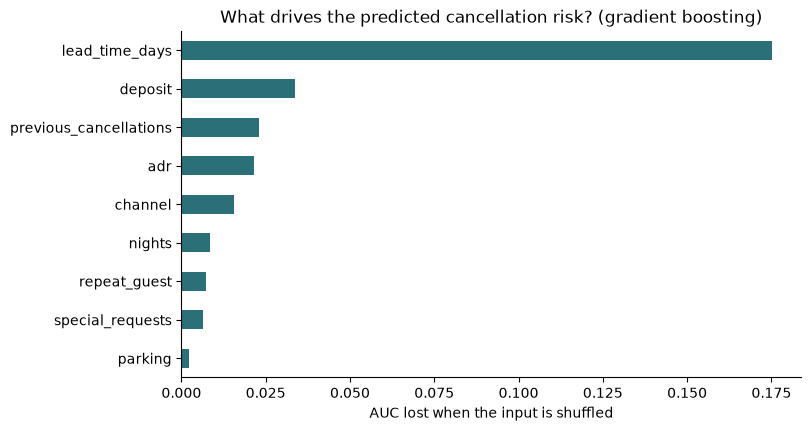

In [14]:
cancel_boost = cancel_models["Gradient boosting"]
imp = permutation_importance(cancel_boost, Xc_test, yc_test, scoring="roc_auc", n_repeats=5, random_state=42)
cancel_imp = pd.Series(imp.importances_mean, index=Xc_test.columns).sort_values()
cancel_imp.tail(9).plot.barh(color="#2b6f78")
plt.title("What drives the predicted cancellation risk? (gradient boosting)")
plt.xlabel("AUC lost when the input is shuffled")
plt.show()

**Reading it.** One input dominates: **lead time** (shuffle it and AUC drops by 0.18, from 0.77 to about 0.60). Far behind come the deposit, previous cancellations, the rate and the channel. The hotel and the month barely matter for cancellations, although they matter a lot for price.

Importance says *which*. It does not say *in which direction*, or whether the effect is a line, a step or a hump. For that, partial dependence. The cell computes its curves for each hotel: the boosting models' average prediction for that hotel's test bookings, as lead time or month changes and nothing else does.

In [15]:
LEAD_GRID = [0, 1, 2, 3, 5, 7, 10, 14, 21, 30, 45, 60, 75, 90, 105, 120, 150, 180, 210, 240, 270, 300]
MONTH_GRID = list(range(1, 13))
pdp = {}
for h in HOTELS:
    r, c = Xr_test[Xr_test["hotel"] == h], Xc_test[Xc_test["hotel"] == h]
    pdp[("rate", "lead", h)] = pd_curve(boost, r, "lead_time_days", LEAD_GRID)
    pdp[("rate", "month", h)] = pd_curve(boost, r, "arrival_month", MONTH_GRID)
    pdp[("cancel", "lead", h)] = 100 * pd_curve(cancel_boost, c, "lead_time_days", LEAD_GRID, proba=True)
    pdp[("cancel", "month", h)] = 100 * pd_curve(cancel_boost, c, "arrival_month", MONTH_GRID, proba=True)
print(pd.DataFrame({h: pdp[("rate", "month", h)].round(0) for h in HOTELS}, index=MONTH_GRID).T)

                 1      2      3      4      5      6      7      8      9   \
Santiago       79.0   77.0   98.0   96.0   96.0   93.0   96.0   97.0  105.0   
Viña del Mar  192.0  182.0  125.0   97.0   89.0   87.0   91.0   89.0   92.0   
Puerto Varas  197.0  190.0  137.0  114.0  108.0  106.0  168.0  124.0  118.0   

                 10     11     12  
Santiago      106.0  106.0   97.0  
Viña del Mar   98.0  109.0  136.0  
Puerto Varas  124.0  131.0  153.0  


The two charts show the predicted rate against lead time (left) and arrival month (right), one line per hotel.

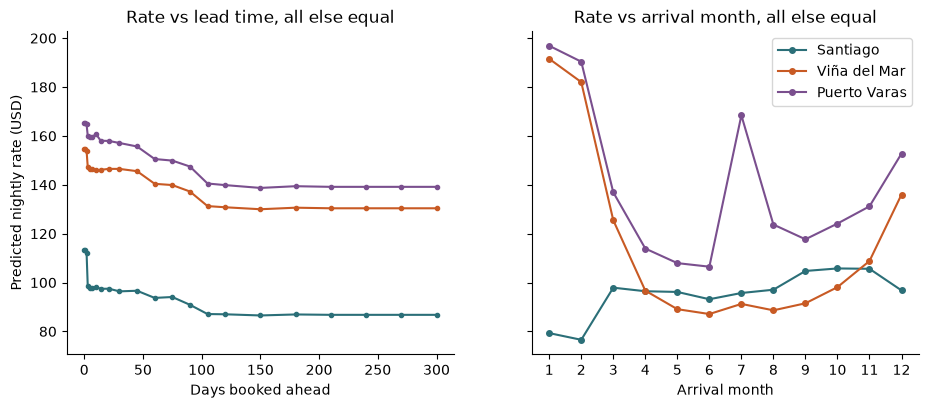

In [16]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for h in HOTELS:
    left.plot(LEAD_GRID, pdp[("rate", "lead", h)], marker="o", ms=3, color=COLORS[h], label=h)
    right.plot(MONTH_GRID, pdp[("rate", "month", h)], marker="o", ms=4, color=COLORS[h], label=h)
left.set(title="Rate vs lead time, all else equal", xlabel="Days booked ahead", ylabel="Predicted nightly rate (USD)")
right.set(title="Rate vs arrival month, all else equal", xlabel="Arrival month", xticks=MONTH_GRID)
right.legend()
plt.show()

**Reading it.** *Lead time:* a **last-minute premium** (bookings made 0–2 days ahead pay USD 6–15 more), a flat middle, then **early-bird discounts** stepping the rate down after 45 and 90 days. *Month:* each hotel has **its own seasons**. Viña del Mar and Puerto Varas peak in January–February, Puerto Varas again in the July winter holidays; Santiago dips in summer and peaks September–November with conferences. A straight line in month could draw none of these; one line per hotel would still miss Puerto Varas's two peaks.

<div class="hz-widget" data-widget="partial-dependence">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_6_Live/">open this session on the course website</a> to use it.</p>
</div>

**Try it:** drag the probe along the lead-time curve for Santiago, then switch on *what a straight line would say*. Where is the line most wrong? Then switch the question to *cancellation risk*.

The chart below shows predicted cancellation risk against lead time, one line per hotel.

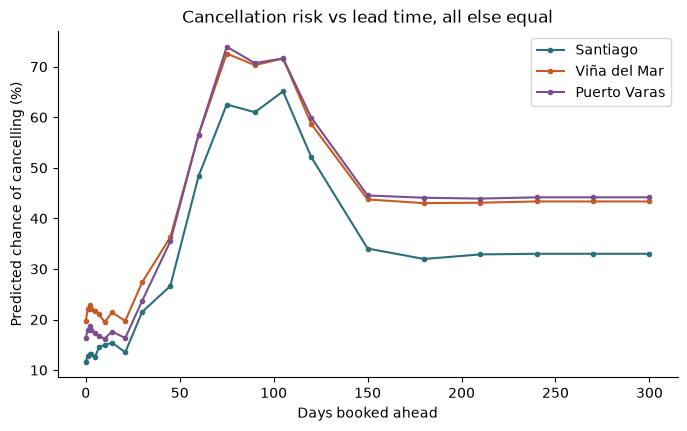

In [17]:
for h in HOTELS:
    plt.plot(LEAD_GRID, pdp[("cancel", "lead", h)], marker="o", ms=3, color=COLORS[h], label=h)
plt.title("Cancellation risk vs lead time, all else equal")
plt.xlabel("Days booked ahead")
plt.ylabel("Predicted chance of cancelling (%)")
plt.legend()
plt.show()

**Reading it.** Risk is a **hump**: about 15–20% for last-minute bookings, rising to about 65–75% for bookings made two to four months ahead, then settling at 35–45%. A logistic regression has one coefficient for lead time, so it can only say "the earlier, the riskier" (or the opposite). That is why the trees win on cancellations.

**Watch out: association, not cause.** The curve says bookings made 90 days ahead *tend to* cancel; it does not say that booking early *makes* guests cancel, or that banning early bookings would cut cancellations. Policies need a test.

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "Partial dependence shows a cancellation risk of about 70% for bookings made 90 days ahead and about 20% for bookings made a week ahead. Which conclusion is justified?", "options": ["Stopping bookings more than 60 days ahead would cut cancellations by two thirds", "Bookings made about three months ahead deserve the most attention in the overbooking forecast", "Booking early causes guests to cancel"], "answer": 1, "why": "The curve describes a pattern the model learned from past bookings. It is perfect for deciding where to look, not for claiming what a new policy would do; that needs a test.", "code": false}</script>
</div>

## <span class="hz-step-n">06</span> From model to decision

A model is only worth what the decisions it improves are worth. Two decisions Altamar takes every day:

- **(a) Revenue management:** what rate to quote for an upcoming booking, and where today's prices are out of line.
- **(b) Operations:** how many rooms to oversell for a busy week.

**(a) A rate card.** The cell describes four upcoming bookings and asks the boosting model for the rate that similar bookings have paid.

In [18]:
base = dict(hotel="Santiago", room_type="Standard", customer_type="Leisure", channel="Direct", deposit="No deposit",
            country="Chile", arrival_month=10, lead_time_days=30, nights=2, weekend_nights=0, adults=2,
            children=0, repeat_guest=0, previous_cancellations=0, special_requests=0, parking=0)
upcoming = pd.DataFrame([
    {**base, "customer_type": "Business", "channel": "Corporate", "lead_time_days": 1, "adults": 1},
    {**base, "hotel": "Viña del Mar", "arrival_month": 1, "weekend_nights": 2, "lead_time_days": 20},
    {**base, "hotel": "Viña del Mar", "arrival_month": 1, "weekend_nights": 2, "lead_time_days": 120},
    {**base, "hotel": "Puerto Varas", "room_type": "Suite", "arrival_month": 7, "nights": 4, "weekend_nights": 2, "lead_time_days": 100},
])[X_rate.columns]
upcoming["model rate (USD)"] = boost.predict(upcoming).round(0)
print(upcoming[["hotel", "room_type", "customer_type", "arrival_month", "lead_time_days", "nights", "model rate (USD)"]])

          hotel room_type customer_type  arrival_month  lead_time_days  \
0      Santiago  Standard      Business             10               1   
1  Viña del Mar  Standard       Leisure              1              20   
2  Viña del Mar  Standard       Leisure              1             120   
3  Puerto Varas     Suite       Leisure              7             100   

   nights  model rate (USD)  
0       2             110.0  
1       2             179.0  
2       2             160.0  
3       4             231.0  


**Where does Altamar under-price?** The cell compares each test booking's actual rate with the model's rate and flags those sold more than 10% below it.

In [19]:
check = Xr_test.assign(actual=yr_test, model_rate=boost.predict(Xr_test))
check["below"] = check["actual"] < 0.9 * check["model_rate"]
check["gap"] = (check["model_rate"] - check["actual"]) * check["nights"] * check["below"]
print(f"{check['below'].sum()} of {len(check):,} test bookings ({check['below'].mean():.0%}) were sold more than 10% below the model's rate,")
print(f"USD {check['gap'].sum():,.0f} below what similar bookings paid, over their stays.\n")
by_channel = check.groupby("channel").agg(bookings=("below", "size"), share_below=("below", "mean"), usd_below=("gap", "sum"))
print(by_channel.assign(share_below=(100 * by_channel["share_below"]).round(0), usd_below=by_channel["usd_below"].round(0)))

160 of 1,491 test bookings (11%) were sold more than 10% below the model's rate,
USD 8,986 below what similar bookings paid, over their stays.

                      bookings  share_below  usd_below
channel                                               
Corporate                  232         13.0      943.0
Direct                     416          9.0     1936.0
Online travel agency       634         10.0     4266.0
Travel agent               209         15.0     1840.0


**Business takeaway.** About one booking in nine was sold well below what comparable bookings paid. The test set is a quarter of two years, so this is roughly **USD 18,000 a year** across the group. The model already knows the agreed channel discounts, so this is extra: **travel-agent** bookings are under-priced most often (15%), then **corporate** ones (13%). Recommendation: review those rate agreements. Some discounts may be deliberate (a loyal client): a question for people, not models.

**(b) Overbooking, week 4 revisited.** In week 4's lab the logistic model scored the 54 bookings arriving at Viña del Mar in the week of 10 February 2025: 24.2 cancellations expected (24 happened), so oversell 20 rooms to keep the chance of walking anyone under 10%. The cell scores the same 54 bookings with three models.

In [20]:
days = (pd.to_datetime(df["arrival_date"]) - pd.Timestamp("2025-02-10")).dt.days
week = (df["hotel"] == "Viña del Mar") & days.between(0, 6)                 # week 4's 54 bookings
rows = []
for name in ["Logistic regression", "Random forest", "Gradient boosting"]:
    p = cancel_models[name].predict_proba(X_cancel[week])[:, 1]
    rng = np.random.default_rng(42)
    simulated = (rng.random((10_000, len(p))) < p).sum(axis=1)               # 10,000 versions of the week
    safe = max(k for k in range(len(p)) if (simulated < k).mean() <= 0.10)
    rows.append({"model": name, "expected cancellations": round(p.sum(), 1), "rooms to oversell (walk risk ≤ 10%)": safe})
print(f"{week.sum()} bookings, {week[Xc_test.index].sum()} of them test bookings. Really cancelled: {df.loc[week, 'canceled'].sum()}.\n")
print(pd.DataFrame(rows).set_index("model"))

54 bookings, 17 of them test bookings. Really cancelled: 24.

                     expected cancellations  \
model                                         
Logistic regression                    24.2   
Random forest                          24.4   
Gradient boosting                      25.0   

                     rooms to oversell (walk risk ≤ 10%)  
model                                                     
Logistic regression                                   20  
Random forest                                         20  
Gradient boosting                                     21  


**Reading it.** On week 4's busy week the three models agree: about 24–25 cancellations, oversell 20–21 rooms. **Watch out**, as in week 4: 37 of these 54 bookings helped train the models, and forests and boosting partly *remember* their training bookings, so this week flatters them. In real use you score the bookings on the books for next week.

Where the better models pay is in **which** rooms to resell. In week 4 we chose a policy with money: an empty room costs USD 400, a walked guest USD 300, so resell every booking with a risk of **0.43** or more. The cell applies the same costs to each model's probabilities for the 1,491 test bookings.

In [21]:
COST_EMPTY_ROOM, COST_WALK = 400, 300                                       # week 4's costs
cancelled = yc_test.values
def policy_cost(p, threshold):
    resold = p >= threshold
    return COST_WALK * (resold & (cancelled == 0)).sum() + COST_EMPTY_ROOM * (~resold & (cancelled == 1)).sum()
print(f"Doing nothing (no overbooking): USD {COST_EMPTY_ROOM * cancelled.sum():,}")
for name in ["Logistic regression", "Random forest", "Gradient boosting"]:
    p = cancel_models[name].predict_proba(Xc_test)[:, 1]
    costs = {t: policy_cost(p, t) for t in np.round(np.arange(0.05, 0.96, 0.01), 2)}
    best = min(costs, key=costs.get)
    print(f"{name:<20} week 4 threshold 0.43: USD {costs[0.43]:,} · its own cheapest, {best:.2f}: USD {costs[best]:,}")

Doing nothing (no overbooking): USD 201,200
Logistic regression  week 4 threshold 0.43: USD 153,100 · its own cheapest, 0.43: USD 153,100
Random forest        week 4 threshold 0.43: USD 138,500 · its own cheapest, 0.51: USD 136,100
Gradient boosting    week 4 threshold 0.43: USD 140,000 · its own cheapest, 0.46: USD 139,200


**Business takeaway.** In week 4 we chose threshold 0.43 with the logistic model: USD 153,100 of empty rooms and walked guests. The same rule with boosting costs USD 140,000; at its own cheapest threshold (0.46), USD 139,200. The forest does a little better (USD 136,100 at 0.51). That is about **USD 14,000–17,000 less on 1,491 bookings**, a quarter of two years: roughly USD 30,000 a year. Better probabilities don't change the method; they make the same policy cheaper. The simulator is week 4's policy, with the logistic model's probabilities.

<div class="hz-widget" data-widget="cost-threshold">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_6_Live/">open this session on the course website</a> to use it.</p>
</div>

**Accuracy is not the only criterion.**

| | Line | Tuned tree | Forest | Boosting |
|---|:--:|:--:|:--:|:--:|
| Rate: typical error | USD 20.5 | USD 13.3 | USD 10.3 | **USD 8.4** |
| Cancellations: AUC | 0.74 | 0.75 | **0.77** | **0.77** |
| Explaining it | coefficients | a flowchart | importance + partial dependence | importance + partial dependence |
| Stability | high | low | high | high for rates (check cancellations in the lab) |
| Training | instant | instant | seconds | seconds |

**Keep the simple model** when the gain is small next to the cost of being wrong, when each decision must be explained (a client, a regulator), when data is scarce, or when the model must live in a spreadsheet.

<div class="hz-widget" data-widget="quiz">
<script type="application/json">{"q": "For which job would Altamar most reasonably keep the linear model?", "options": ["Setting nightly rates for the 7,300 room-nights it sells a year", "Explaining to a corporate client, line by line, why their negotiated rate is what it is", "Ranking which 150 bookings are most likely to cancel"], "answer": 1, "why": "Pricing and ranking are high-volume jobs where boosting's accuracy is worth real money. A negotiation needs an explanation in plain numbers for one booking, where a coefficient table shines.", "code": false}</script>
</div>

## <span class="hz-step-n">07</span> Presenting to management

Altamar's general manager has ten minutes and one question: *what should we do?* The **pyramid principle** answers it top-down:

1. **The recommendation first**, in one sentence, with a number.
2. **Three arguments**, each answering "why should I believe that?".
3. **Evidence** under each argument: one chart or one number per box.

We usually tell a story in the order we did the analysis: data, models, results, and the recommendation at the end. If the meeting runs late, the recommendation is what gets cut.

<div class="hz-widget" data-widget="pyramid">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/sessions/Session_6_Live/">open this session on the course website</a> to use it.</p>
</div>

**Altamar's pyramid, from today's numbers.**

- **Key message:** price with gradient boosting and feed its cancellation risks into week 4's overbooking rule: the typical pricing error falls from USD 20 to USD 8 a night.
- **1. The model prices like our best revenue manager.** R² 0.74 (line) → 0.89 (week 5's tree) → 0.96 on bookings it never saw.
- **2. We know what drives price and cancellations.** Month, room and hotel set the price; each hotel has its own seasons; risk peaks 2–4 months out.
- **3. It pays off in two decisions.** One booking in nine sold more than 10% below similar ones; week 4's overbooking rule costs USD 140,000 instead of 153,100.

## <span class="hz-step-n">08</span> What's next: Business Analytics II

Our best rate model still misses by USD 8 a night, and the best cancellation model is far from perfect. Some of what moves a guest is not in the booking form at all. It is in what guests **write**.

Altamar has thousands of guest reviews: "the volcano view was worth every peso", "the corporate floor was noisy". Ratings and reviews explain what our columns cannot: why a hotel can charge more, why a guest does not come back.

**Business Analytics II · Text, NLP and LLMs** starts there: turning text into numbers, finding topics and sentiment in reviews, and using large language models to read thousands of them for you.

## <span class="hz-step-n">09</span> Case clinic: comparison and presentation

This is the last step of the [applied case](https://hizocar.github.io/mba-business-analytics-1/case/case/). In your team, with the [case toolkit](https://hizocar.github.io/mba-business-analytics-1/case/Case_Toolkit/):

1. **Compare models.** Run sections **09 Random forest and gradient boosting** and **10 Scoreboard**: linear model, tuned tree, random forest and gradient boosting, on the **same test data**, with the metric you chose in week 4.
2. **Explain the best one.** Run section **11 What drives the predictions**: permutation importance, then partial dependence for your top two or three inputs. One sentence per chart: what it means for the business.
3. **Decide.** Choose a model: accuracy, stability, explainability, cost of errors.
4. **Write three recommendations** someone could act on next week.

**Build the 10-slide pyramid.** A skeleton that works:

| Slide | Content |
|:--:|---|
| 1 | The key message: recommendation + the number that justifies it |
| 2 | The business question and who decides |
| 3–4 | Argument 1 and its evidence (e.g. the scoreboard) |
| 5–6 | Argument 2 and its evidence (e.g. importance, one partial dependence chart) |
| 7–8 | Argument 3 and its evidence (e.g. money or a decision rule) |
| 9 | Limitations and what you would test next |
| 10 | The three recommendations, with an owner each |

Check the [rubric](https://hizocar.github.io/mba-business-analytics-1/case/case/) before you hand in: the notebook runs top to bottom, and every chart supports an argument.